# JS08 Tugas Lab 2: HDBSCAN pada Dataset Iris

Dataset yang dipilih dari `sklearn.datasets` adalah **iris**. Datanya punya 150 sampel, empat fitur, dan tiga kelas asli: setosa, versicolor, dan virginica.

Yang menarik untuk diuji, dua kelas terakhir saling tumpang tindih pada beberapa fitur. Jadi pertanyaan tugas ini bukan cuma berapa cluster yang terbentuk, tapi apakah hasilnya cocok dengan tiga label aslinya.


## 1. Import Library dan Load Data


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, davies_bouldin_score,
                             normalized_mutual_info_score, silhouette_score)
from sklearn.preprocessing import StandardScaler
import hdbscan


In [2]:
iris = load_iris()
X = iris.data
y_true = iris.target

print('Nama fitur:', iris.feature_names)
print('Nama kelas:', iris.target_names)
print('Bentuk data:', X.shape)
pd.DataFrame(X, columns=iris.feature_names).head()


Nama fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Nama kelas: ['setosa' 'versicolor' 'virginica']
Bentuk data: (150, 4)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


Fitur distandarkan karena keempatnya punya satuan yang sama (cm) tapi rentangnya berbeda, dan HDBSCAN menghitung jarak antar titik.


In [3]:
X_scaled = StandardScaler().fit_transform(X)
pd.DataFrame(X_scaled, columns=iris.feature_names).describe().T[['mean', 'std', 'min', 'max']]


,mean,std,min,max
sepal length (cm),-1.468455e-15,1.00335,-1.870024,2.492019
sepal width (cm),-1.823726e-15,1.00335,-2.433947,3.090775
petal length (cm),-1.610564e-15,1.00335,-1.567576,1.785832
petal width (cm),-9.473903e-16,1.00335,-1.447076,1.712096


## 2. Clustering dengan HDBSCAN


In [4]:
hdb = hdbscan.HDBSCAN().fit(X_scaled)
labels = hdb.labels_

jumlah_cluster = len(set(labels)) - (1 if -1 in labels else 0)
jumlah_noise = (labels == -1).sum()

print(f'Jumlah cluster yang terbentuk: {jumlah_cluster}')
print(f'Banyaknya noise: {jumlah_noise} dari {len(labels)} ({jumlah_noise / len(labels) * 100:.1f}%)')
print(f'Distribusi label: {np.bincount(labels + 1)}')


Jumlah cluster yang terbentuk: 2
Banyaknya noise: 2 dari 150 (1.3%)
Distribusi label: [ 2 99 49]


**Hasil:** terbentuk **2 cluster** dan **2 titik noise**.

Jadi HDBSCAN tidak menemukan tiga kelompok seperti label aslinya. Ini sudah terlihat dari jumlahnya, dan penyebabnya dibahas di bagian analisis.


## 3. Visualisasi dengan PCA

Data iris punya empat dimensi, sedangkan scatter plot hanya bisa menampilkan dua. PCA dipakai untuk memproyeksikan ke dua komponen utama, yaitu dua arah yang paling banyak menyimpan keragaman data.


In [5]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f'Keragaman yang dijelaskan: {pca.explained_variance_ratio_.sum() * 100:.1f}%')


Keragaman yang dijelaskan: 95.8%


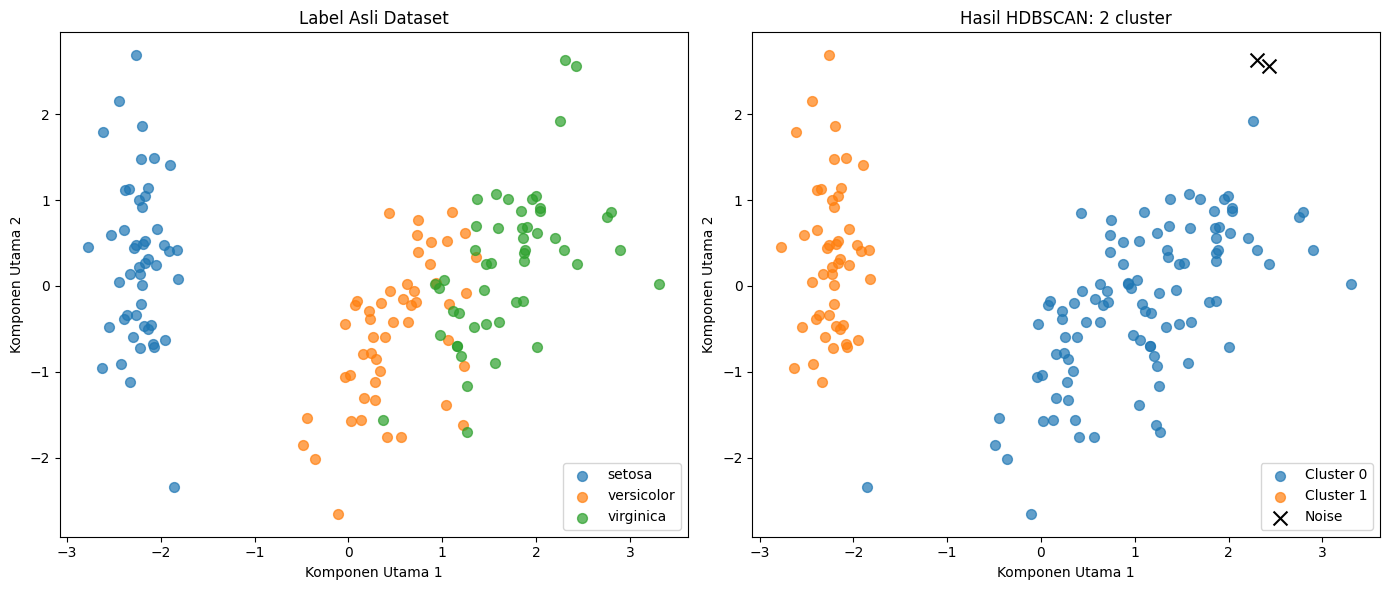

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for label in np.unique(y_true):
    mask = y_true == label
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=50,
                    label=iris.target_names[label], alpha=0.7)
axes[0].set_title('Label Asli Dataset')
axes[0].set_xlabel('Komponen Utama 1')
axes[0].set_ylabel('Komponen Utama 2')
axes[0].legend()

noise = labels == -1
for label in np.unique(labels[~noise]):
    mask = (labels == label) & ~noise
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1], s=50,
                    label=f'Cluster {label}', alpha=0.7)
axes[1].scatter(X_pca[noise, 0], X_pca[noise, 1], s=100, c='black', marker='x',
                label='Noise')
axes[1].set_title(f'Hasil HDBSCAN: {jumlah_cluster} cluster')
axes[1].set_xlabel('Komponen Utama 1')
axes[1].set_ylabel('Komponen Utama 2')
axes[1].legend()

plt.tight_layout()
plt.show()


Dua komponen utama menangkap hampir seluruh keragaman data, jadi gambar ini cukup mewakili sebaran aslinya.

Pada gambar kiri terlihat kelas setosa terpisah jauh di kiri, sementara versicolor dan virginica berdempetan di kanan. Pada gambar kanan, HDBSCAN menggabungkan kedua kelas yang berdempetan itu menjadi satu cluster, dan menyisakan dua titik sebagai noise.


## 4. Analisis: Apakah Sesuai dengan Label Asli?


In [7]:
mask_bersih = labels != -1
X_bersih = X_scaled[mask_bersih]
labels_bersih = labels[mask_bersih]

ari = adjusted_rand_score(y_true, labels)
nmi = normalized_mutual_info_score(y_true, labels)

print(f'Adjusted Rand Index : {ari:.4f}')
print(f'Normalized Mutual Information: {nmi:.4f}')


Adjusted Rand Index : 0.5394
Normalized Mutual Information: 0.6778


In [8]:
tabel_silang = pd.crosstab(
    pd.Series(labels, name='Cluster HDBSCAN'),
    pd.Series([iris.target_names[t] for t in y_true], name='Spesies Asli'),
)
tabel_silang


Spesies Asli,setosa,versicolor,virginica
Cluster HDBSCAN,,,
-1,0,0,2
0,1,50,48
1,49,0,0


In [9]:
print(f'Silhouette Score : {silhouette_score(X_bersih, labels_bersih):.4f}')
print(f'Davies-Bouldin Index : {davies_bouldin_score(X_bersih, labels_bersih):.4f}')


Silhouette Score : 0.5853
Davies-Bouldin Index : 0.5833


In [10]:
# Uji beberapa pengaturan untuk melihat apakah tiga cluster bisa muncul
uji = []
for mcs, ms in [(5, 2), (5, 5), (10, 5), (15, 5), (25, 5)]:
    model = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms).fit(X_scaled)
    lab = model.labels_
    uji.append({
        'min_cluster_size': mcs,
        'min_samples': ms,
        'Jumlah cluster': len(set(lab)) - (1 if -1 in lab else 0),
        'Noise': (lab == -1).sum(),
        'ARI': round(adjusted_rand_score(y_true, lab), 4),
    })

pd.DataFrame(uji)


,min_cluster_size,min_samples,Jumlah cluster,Noise,ARI
0,5,2,2,0,0.5681
1,5,5,2,2,0.5394
2,10,5,2,2,0.5394
3,15,5,2,2,0.5394
4,25,5,2,2,0.5394


**Jawaban: hasilnya tidak sepenuhnya sesuai dengan label asli.**

HDBSCAN menemukan 2 cluster, sedangkan dataset aslinya punya 3 spesies. Tabel silang memperlihatkan sebabnya: satu cluster berisi 49 setosa, dan cluster kedua berisi 50 versicolor, 48 virginica, dan 1 setosa yang menyendiri. Dua titik sisa ditandai sebagai noise, keduanya dari kelas virginica.

Jadi setosa hampir seluruhnya berhasil dipisahkan, tapi versicolor dan virginica bergabung menjadi satu kelompok. Satu setosa yang ikut ke cluster besar itu contoh titik yang secara kepadatan lebih dekat ke kelompok versicolor daripada ke kelompoknya sendiri.

Angka ARI sekitar 0.54 dan NMI sekitar 0.68 mendukung bacaan itu. Nilainya cukup tinggi untuk menunjukkan ada kecocokan nyata dengan label asli, tapi tidak mendekati 1 yang berarti pencocokan sempurna.

Ada dua penyebab, dan keduanya menarik:

1. **Datanya memang tumpang tindih.** Versicolor dan virginica beririsan pada fitur panjang dan lebar petal. Dari sudut pandang kepadatan, keduanya menyatu menjadi satu gumpalan yang rapat, bukan dua kelompok yang terpisah.
2. **HDBSCAN tidak memakai label.** Ia mengelompokkan berdasarkan kerapatan, bukan berdasarkan kemiripan dengan kelas. Kalau dua kelas saling beririsan, menggabungkannya justru keputusan yang benar menurut ukuran kepadatan.

Percobaan pada tabel terakhir menunjukkan jumlah cluster tetap 2 di semua pengaturan `min_cluster_size` dan `min_samples` yang dicoba. Yang berubah hanya jumlah noise dan nilai ARI-nya. Artinya, hasil dua cluster itu bukan efek parameter yang kurang tepat, melainkan memang struktur kepadatan data iris hanya punya dua gumpalan besar.


## Kesimpulan

HDBSCAN pada dataset iris menghasilkan 2 cluster dengan 2 titik noise. Setosa hampir seluruhnya terpisah, sedangkan versicolor dan virginica bergabung menjadi satu cluster.

Hasil ini tidak sama dengan tiga label asli, dan itu bukan kesalahan algoritmanya. HDBSCAN mengelompokkan berdasarkan kepadatan, sementara dua kelas terakhir memang beririsan di ruang fitur. Kalau tujuannya mereproduksi label, model terawasi lebih tepat. Kalau tujuannya menemukan kelompok alami dalam data, hasil dua cluster ini justru menggambarkan struktur aslinya dengan lebih jujur.
